# Bagian B: Logistic Regression untuk Memprediksi Churn Pelanggan Telco

Mata kuliah Fundamen Sains Data, Tugas Kelompok Linear Regression dan Logistic Regression.

Anggota kelompok:

| Nama | NIM |
|---|---|
| Gusti Surya Aditama | 25523053 |
| Muhammad Lutfi Syarif | 25523021 |
| Naufal Alaam Najib | 25523063 |

Di bagian ini kami membangun model Logistic Regression untuk memprediksi apakah seorang pelanggan akan berhenti berlangganan (churn). Urutannya mengikuti soal: deskripsi data (B1), eksplorasi (B2), preprocessing (B3), pemilihan fitur (B4), pembagian data (B5), pemodelan (B6), evaluasi (B7), lalu analisis performa (B8).

## B1. Deskripsi Dataset

Dataset yang kami pakai adalah *Telco Customer Churn (IBM dataset)* dari Kaggle: <https://www.kaggle.com/datasets/yeanzc/telco-customer-churn-ibm-dataset>

Sel di bawah mengimpor library dan memuat data. Notebook mencari file `Telco_customer_churn.xlsx` di folder `data/` (dan di folder kerja Colab). Kalau tidak ketemu, Colab akan meminta file itu diunggah.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             roc_auc_score, classification_report)
from statsmodels.stats.outliers_influence import variance_inflation_factor

sns.set_style("whitegrid")
RANDOM_STATE = 42

# Mencari file data: folder data/ (repositori), folder kerja Colab, atau langsung dari repositori GitHub
RAW_URL = "https://raw.githubusercontent.com/gustisuryaa/fsd-tugas-regresi/main/data/Telco_customer_churn.xlsx"
FILE = next((p for p in ["data/Telco_customer_churn.xlsx", "Telco_customer_churn.xlsx"] if os.path.exists(p)), RAW_URL)

try:
    df = pd.read_excel(FILE)
except Exception:
    from google.colab import files
    files.upload()   # cadangan terakhir: pilih file Telco_customer_churn.xlsx secara manual
    df = pd.read_excel("Telco_customer_churn.xlsx")
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [2]:
print("Jumlah baris dan kolom :", df.shape)
df.info()

Jumlah baris dan kolom : (7043, 33)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16 

In [3]:
print(df["Churn Label"].value_counts())
print(df["Churn Label"].value_counts(normalize=True) * 100)

Churn Label
No     5174
Yes    1869
Name: count, dtype: int64
Churn Label
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Datanya berisi 7.043 pelanggan sebuah perusahaan telekomunikasi di California, dengan 33 kolom. Satu baris adalah satu pelanggan.

Variabel target adalah `Churn Label` (Yes/No), yaitu apakah pelanggan berhenti berlangganan. Kelas positif (Yes) berarti pelanggan churn, kelas negatif (No) berarti pelanggan bertahan.

Arti tiap kolom:

| Kolom | Arti |
|---|---|
| CustomerID | ID unik pelanggan |
| Count | konstanta bernilai 1 |
| Country, State, City, Zip Code | lokasi pelanggan |
| Lat Long, Latitude, Longitude | koordinat lokasi |
| Gender | jenis kelamin |
| Senior Citizen | apakah pelanggan lansia (Yes/No) |
| Partner | apakah punya pasangan |
| Dependents | apakah punya tanggungan |
| Tenure Months | lama berlangganan (bulan) |
| Phone Service | berlangganan telepon |
| Multiple Lines | punya lebih dari satu jalur telepon |
| Internet Service | jenis internet (DSL, Fiber optic, No) |
| Online Security, Online Backup, Device Protection, Tech Support | layanan tambahan |
| Streaming TV, Streaming Movies | layanan streaming |
| Contract | jenis kontrak (Month-to-month, One year, Two year) |
| Paperless Billing | tagihan tanpa kertas |
| Payment Method | metode pembayaran |
| Monthly Charges | biaya bulanan |
| Total Charges | total biaya selama berlangganan |
| Churn Label | target (Yes/No) |
| Churn Value | target dalam bentuk 1/0 |
| Churn Score | skor risiko churn dari IBM |
| CLTV | estimasi nilai pelanggan seumur hidup |
| Churn Reason | alasan churn (hanya terisi untuk pelanggan yang churn) |

Beberapa kolom di atas tidak akan dipakai: kolom identitas dan lokasi, serta kolom yang berkaitan langsung dengan target karena bisa menyebabkan data leakage. Alasannya kami jelaskan di B3.

## B2. Eksplorasi dan Visualisasi Data

Statistik deskriptif kolom numerik:

In [4]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


Dari statistik deskriptif:

- Rata-rata `Tenure Months` sekitar 32,4 bulan (rentang 0 sampai 72) dan rata-rata `Monthly Charges` sekitar 64,76.
- `Count` selalu bernilai 1 (std = 0), jadi tidak informatif dan akan dibuang.
- Rata-rata `Churn Value` sekitar 0,265, artinya sekitar 26,5% pelanggan churn.
- `Zip Code`, `Latitude`, dan `Longitude` hanya penanda lokasi, jadi rata-rata dan simpangan bakunya tidak punya arti.

Visualisasi 1: distribusi kelas target.

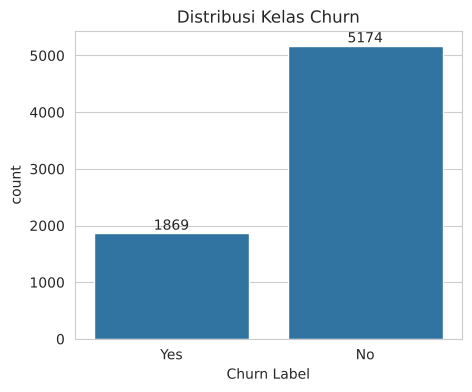

In [5]:
plt.figure(figsize=(5,4))
ax = sns.countplot(x="Churn Label", data=df)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.title("Distribusi Kelas Churn")
plt.show()

Kelas "No" (bertahan) ada 5.174 pelanggan (73,5%), sedangkan "Yes" (churn) 1.869 (26,5%). Datanya tidak seimbang, jadi accuracy bisa menyesatkan: model yang selalu menebak "No" saja sudah dapat akurasi sekitar 73,5%. Ini kami tangani di B3.

Visualisasi 2: box plot fitur numerik per kelas.

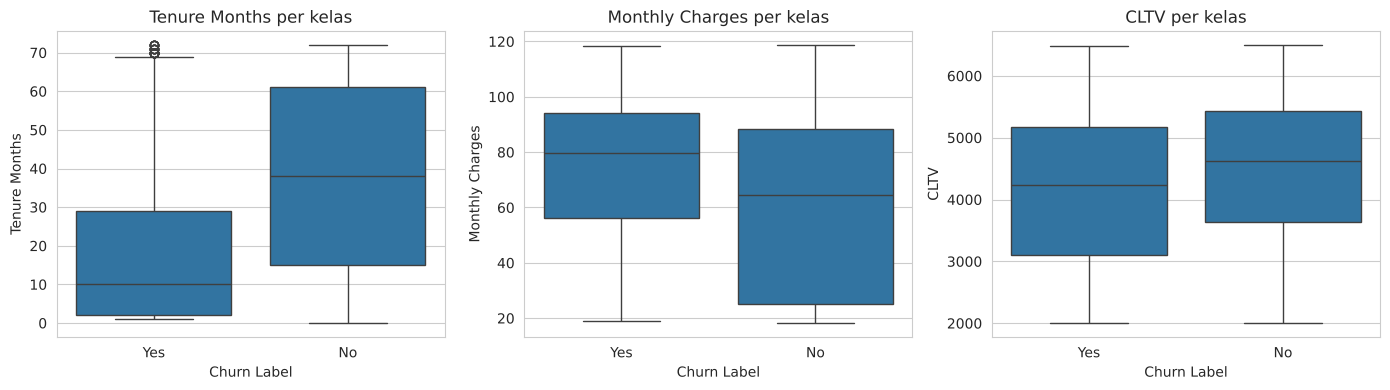

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col in zip(axes, ["Tenure Months", "Monthly Charges", "CLTV"]):
    sns.boxplot(x="Churn Label", y=col, data=df, ax=ax)
    ax.set_title(col + " per kelas")
plt.tight_layout()
plt.show()

- `Tenure Months`: pelanggan yang churn masa berlangganannya jauh lebih pendek (median sekitar 10 bulan, dibanding sekitar 38 bulan pada yang bertahan). Pelanggan baru paling mudah pergi.
- `Monthly Charges`: pelanggan yang churn cenderung membayar lebih mahal (median sekitar 80, dibanding sekitar 64).
- `CLTV`: median pelanggan churn sedikit lebih rendah (sekitar 4.238 vs 4.620), tapi sebarannya banyak yang tumpang tindih, jadi kolom ini tidak terlalu membedakan kelas.

Visualisasi 3: heatmap korelasi. `Total Charges` terbaca sebagai teks, jadi diubah ke angka dulu.

Nilai kosong Total Charges: 11


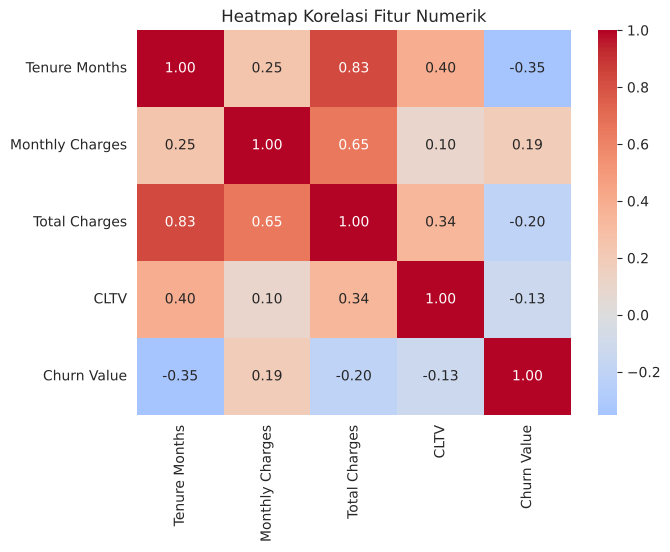

In [7]:
df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")
print("Nilai kosong Total Charges:", df["Total Charges"].isna().sum())

num_cols = ["Tenure Months", "Monthly Charges", "Total Charges", "CLTV", "Churn Value"]
plt.figure(figsize=(7,5))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Heatmap Korelasi Fitur Numerik")
plt.show()

- `Tenure Months` berkorelasi negatif dengan `Churn Value` (sekitar -0,35): makin lama berlangganan, makin kecil kemungkinan churn.
- `Monthly Charges` berkorelasi positif lemah dengan churn (sekitar +0,19), `Total Charges` negatif (sekitar -0,20), dan `CLTV` negatif lemah (sekitar -0,13).
- `Tenure Months` dan `Total Charges` berkorelasi sangat kuat (sekitar 0,83). Ini tanda multikolinearitas yang kami bahas di B4.

## B3. Preprocessing

### 3.1 Missing values

Kami cek dulu kolom mana saja yang punya nilai kosong.

In [8]:
df.isna().sum()[lambda s: s > 0]

Total Charges      11
Churn Reason     5174
dtype: int64

Ada dua kolom dengan nilai kosong:

- `Churn Reason` kosong untuk 5.174 pelanggan, sama dengan jumlah yang tidak churn. Alasan churn baru ada setelah pelanggan berhenti, jadi kolom ini bocoran dari target dan kami buang.
- `Total Charges` kosong di 11 baris. Barisnya kami lihat dulu.

In [9]:
df[df["Total Charges"].isna()][["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", "Churn Label"]]

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Label
2234,4472-LVYGI,0,52.55,NaN,No
2438,3115-CZMZD,0,20.25,NaN,No
2568,5709-LVOEQ,0,80.85,NaN,No
2667,4367-NUYAO,0,25.75,NaN,No
2856,1371-DWPAZ,0,56.05,NaN,No
4331,7644-OMVMY,0,19.85,NaN,No
4687,3213-VVOLG,0,25.35,NaN,No
5104,2520-SGTTA,0,20.00,NaN,No
5719,2923-ARZLG,0,19.70,NaN,No
6772,4075-WKNIU,0,73.35,NaN,No


Semua 11 baris itu punya `Tenure Months = 0`, yaitu pelanggan yang baru mendaftar dan belum pernah ditagih (dan semuanya berlabel tidak churn). Jadi nilai yang masuk akal untuk `Total Charges` memang 0, dan kami isi dengan 0, bukan mean atau median.

In [10]:
df["Total Charges"] = df["Total Charges"].fillna(0)
print("Sisa nilai kosong Total Charges:", df["Total Charges"].isna().sum())

Sisa nilai kosong Total Charges: 0


### 3.2 Data duplikat

In [11]:
print("Baris duplikat penuh :", df.duplicated().sum())
print("CustomerID duplikat  :", df["CustomerID"].duplicated().sum())

Baris duplikat penuh : 0
CustomerID duplikat  : 0


Tidak ada baris duplikat dan `CustomerID` unik untuk setiap pelanggan, jadi tidak ada yang dihapus.

### 3.3 Outlier

Kami cek outlier kolom numerik dengan aturan IQR (di luar Q1 - 1,5×IQR dan Q3 + 1,5×IQR).

In [12]:
for col in ["Tenure Months", "Monthly Charges", "Total Charges"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5*iqr) | (df[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n_out} outlier")

Tenure Months: 0 outlier
Monthly Charges: 0 outlier
Total Charges: 0 outlier


Ketiga kolom numerik tidak punya outlier menurut aturan IQR. Rentang nilainya juga wajar (tenure 0 sampai 72 bulan, tagihan bulanan sekitar 18 sampai 119), jadi tidak ada yang dibuang.

### 3.4 Membuang kolom yang tidak dipakai

| Kolom | Alasan dibuang |
|---|---|
| CustomerID | pengenal unik, tidak punya makna prediktif |
| Count | konstan (selalu 1) |
| Country, State | konstan (semua United States dan California) |
| City, Zip Code, Lat Long, Latitude, Longitude | lokasi dengan nilai unik sangat banyak (misalnya 1.652 zip code), tidak cocok untuk model linear sederhana |
| Churn Value | bentuk numerik dari target (leakage) |
| Churn Score | skor churn buatan IBM. Pelanggan yang churn semuanya bernilai 65 ke atas (rata-rata sekitar 82), sedangkan yang bertahan rata-rata sekitar 50. Skor ini sangat mungkin sudah memakai informasi churn, jadi kami anggap leakage |
| Churn Reason | hanya terisi setelah pelanggan churn (leakage) |
| CLTV | estimasi turunan IBM yang cara hitungnya tidak transparan, dan dari box plot hanya sedikit membedakan kelas |

In [13]:
drop_cols = ["CustomerID", "Count", "Country", "State", "City", "Zip Code", "Lat Long",
             "Latitude", "Longitude", "Churn Value", "Churn Score", "Churn Reason", "CLTV"]
data = df.drop(columns=drop_cols).copy()
print(data.shape)
data.head()

(7043, 20)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,Yes
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes


### 3.5 Encoding fitur kategorikal

- Target `Churn Label` diubah menjadi 1 (Yes) dan 0 (No).
- Nilai "No internet service" dan "No phone service" digabung ke "No", karena informasinya sudah ada di `Internet Service` dan `Phone Service`. Ini mengurangi kolom yang redundan.
- Kolom biner Yes/No dan `Gender` diubah menjadi 0/1.
- Kolom dengan lebih dari dua kategori (`Internet Service`, `Contract`, `Payment Method`) di-one-hot encode dengan `drop_first=True` supaya tidak kena dummy variable trap.

In [14]:
data["Churn"] = (data["Churn Label"] == "Yes").astype(int)
data = data.drop(columns="Churn Label")

data = data.replace({"No internet service": "No", "No phone service": "No"})

binary_cols = ["Senior Citizen", "Partner", "Dependents", "Phone Service", "Multiple Lines",
               "Online Security", "Online Backup", "Device Protection", "Tech Support",
               "Streaming TV", "Streaming Movies", "Paperless Billing"]
for c in binary_cols:
    data[c] = (data[c] == "Yes").astype(int)
data["Gender"] = (data["Gender"] == "Male").astype(int)   # 1 = Male

data = pd.get_dummies(data, columns=["Internet Service", "Contract", "Payment Method"], drop_first=True, dtype=int)
print(data.shape)
data.head()

(7043, 24)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Online Security,Online Backup,Device Protection,...,Monthly Charges,Total Charges,Churn,Internet Service_Fiber optic,Internet Service_No,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,1,0,0,0,2,1,0,1,1,0,...,53.85,108.15,1,0,0,0,0,0,0,1
1,0,0,0,1,2,1,0,0,0,0,...,70.70,151.65,1,1,0,0,0,0,1,0
2,0,0,0,1,8,1,1,0,0,1,...,99.65,820.50,1,1,0,0,0,0,1,0
3,0,0,1,1,28,1,1,0,0,1,...,104.80,3046.05,1,1,0,0,0,0,1,0
4,1,0,0,1,49,1,1,0,1,1,...,103.70,5036.30,1,1,0,0,0,0,0,0


### 3.6 Ketidakseimbangan kelas

Kelas churn hanya sekitar 26,5%. Akibatnya model cenderung condong ke kelas mayoritas, sehingga recall untuk pelanggan churn rendah walaupun accuracy-nya tampak bagus.

Untuk menanganinya kami pakai `class_weight='balanced'` pada `LogisticRegression`, yang memberi bobot lebih besar pada kelas minoritas tanpa mengubah jumlah data. Kami pilih ini dibanding resampling karena lebih sederhana dan tidak membuat data sintetis. Di B7 hasilnya dibandingkan dengan model tanpa pembobotan.

### 3.7 Scaling

Scaling (standardisasi) dilakukan setelah pembagian data di B5. `fit`-nya hanya pada data latih supaya tidak terjadi data leakage.

## B4. Pemilihan Fitur

Kami memakai tiga alat: korelasi dengan target, uji chi-square (`SelectKBest`), dan VIF untuk multikolinearitas.

Pertama, korelasi tiap fitur dengan target.

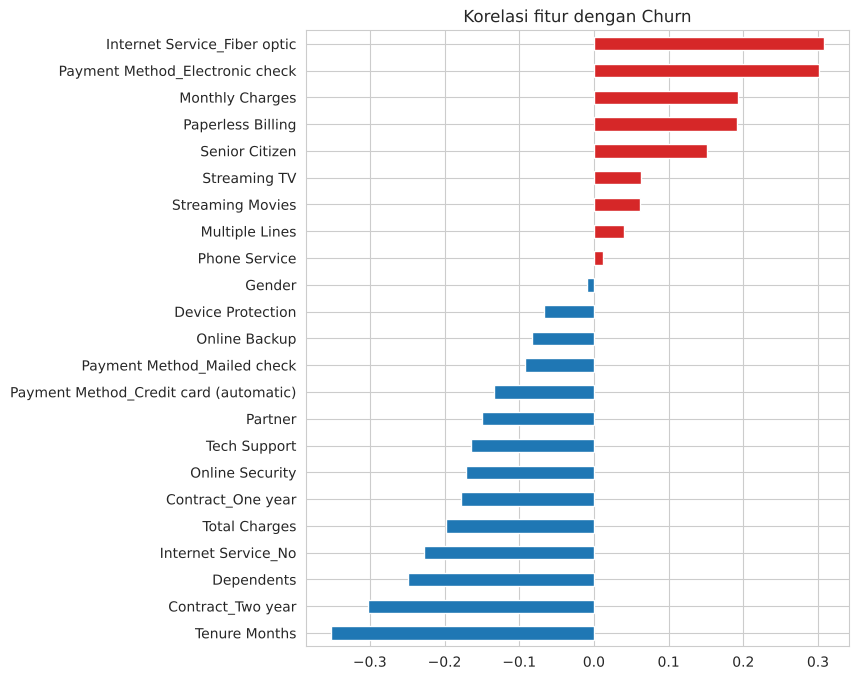

In [15]:
corr = data.corr()["Churn"].drop("Churn").sort_values()
plt.figure(figsize=(7,8))
corr.plot(kind="barh", color=np.where(corr > 0, "tab:red", "tab:blue"))
plt.title("Korelasi fitur dengan Churn")
plt.show()

`Contract_Two year`, `Tenure Months`, dan `Contract_One year` berkorelasi negatif dengan churn (menurunkan peluang churn). `Internet Service_Fiber optic`, `Payment Method_Electronic check`, dan `Monthly Charges` berkorelasi positif. `Gender` dan `Phone Service` hampir tidak berkorelasi.

Kedua, uji chi-square dengan `SelectKBest`. Uji ini butuh nilai non-negatif, jadi fitur diskalakan ke rentang 0 sampai 1 dengan `MinMaxScaler` hanya untuk keperluan uji.

In [16]:
X_all = data.drop(columns="Churn")
y_all = data["Churn"]

X_mm = MinMaxScaler().fit_transform(X_all)
selector = SelectKBest(chi2, k="all").fit(X_mm, y_all)
chi_df = pd.DataFrame({"Fitur": X_all.columns, "Chi2": selector.scores_, "p-value": selector.pvalues_}).sort_values("Chi2", ascending=False)
chi_df

,Fitur,Chi2,p-value
19,Contract_Two year,488.578090,2.905390e-108
21,Payment Method_Electronic check,426.422767,9.760677e-95
16,Internet Service_Fiber optic,374.476216,1.984260e-83
3,Dependents,334.563859,9.745254e-75
17,Internet Service_No,286.520193,2.849642e-64
4,Tenure Months,226.096162,4.233851e-51
18,Contract_One year,176.123171,3.403606e-40
7,Online Security,147.295858,6.761696e-34
10,Tech Support,135.559783,2.490549e-31
1,Senior Citizen,134.351545,4.576959e-31


Ketiga, VIF (Variance Inflation Factor) untuk melihat multikolinearitas. VIF di atas 10 biasanya dianggap bermasalah.

In [17]:
Xv = X_all.astype(float).copy()
Xv.insert(0, "const", 1.0)
vif = pd.DataFrame({"Fitur": X_all.columns,
                    "VIF": [variance_inflation_factor(Xv.values, i+1) for i in range(len(X_all.columns))]}
                   ).sort_values("VIF", ascending=False)
vif

,Fitur,VIF
14,Monthly Charges,865.450345
16,Internet Service_Fiber optic,148.341096
17,Internet Service_No,104.312137
5,Phone Service,34.879137
12,Streaming Movies,24.127021
11,Streaming TV,24.069355
15,Total Charges,10.788463
4,Tenure Months,7.526158
6,Multiple Lines,7.276556
9,Device Protection,6.927092


Hasil chi-square: hanya `Gender` (p ≈ 0,61) dan `Phone Service` (p ≈ 0,76) yang tidak signifikan (p ≥ 0,05). Keduanya kami buang.

Hasil VIF: `Monthly Charges` (sekitar 865), `Internet Service_Fiber optic` (sekitar 148), `Internet Service_No` (sekitar 104), dan `Phone Service` (sekitar 35) sangat tinggi. `Total Charges` sekitar 10,8.

Keputusan kami:

- `Total Charges` dibuang. Korelasinya dengan `Tenure Months` tinggi (0,83), dan nilainya pada dasarnya mendekati lama berlangganan dikali tagihan bulanan, jadi informasinya sudah terwakili.
- `Gender` dan `Phone Service` dibuang karena tidak berhubungan signifikan dengan churn (dan `Phone Service` juga sangat berkorelasi dengan fitur lain).
- Fitur lain dipertahankan.

Sel berikut menerapkan keputusan itu dan menghitung ulang VIF.

In [18]:
low_sig = chi_df.loc[chi_df["p-value"] >= 0.05, "Fitur"].tolist()
drop_feat = list(set(["Total Charges"] + low_sig))
selected = [c for c in X_all.columns if c not in drop_feat]
print("Fitur dibuang      :", drop_feat)
print("Jumlah fitur dipakai:", len(selected))
print("Fitur dipakai      :", selected)

Xv2 = X_all[selected].astype(float).copy()
Xv2.insert(0, "const", 1.0)
pd.DataFrame({"Fitur": selected,
              "VIF": [variance_inflation_factor(Xv2.values, i+1) for i in range(len(selected))]}
            ).sort_values("VIF", ascending=False)

Fitur dibuang      : ['Phone Service', 'Gender', 'Total Charges']
Jumlah fitur dipakai: 20
Fitur dipakai      : ['Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Multiple Lines', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Paperless Billing', 'Monthly Charges', 'Internet Service_Fiber optic', 'Internet Service_No', 'Contract_One year', 'Contract_Two year', 'Payment Method_Credit card (automatic)', 'Payment Method_Electronic check', 'Payment Method_Mailed check']


,Fitur,VIF
12,Monthly Charges,33.521006
13,Internet Service_Fiber optic,10.098428
14,Internet Service_No,4.813618
3,Tenure Months,2.776020
16,Contract_Two year,2.603953
9,Streaming TV,2.442485
10,Streaming Movies,2.424416
18,Payment Method_Electronic check,1.973636
4,Multiple Lines,1.920684
19,Payment Method_Mailed check,1.840171


Setelah `Total Charges` dan `Phone Service` dibuang, VIF turun banyak: `Monthly Charges` jadi sekitar 33,5, `Internet Service_Fiber optic` sekitar 10,1, dan fitur lain di bawah 5. `Monthly Charges` masih tinggi. Kami tetap mempertahankannya dan `Fiber optic` karena keduanya berhubungan kuat dengan churn, tapi koefisien keduanya perlu dibaca hati-hati (lihat B6).

Satu catatan: uji chi-square dan VIF di atas dihitung dari seluruh data sebelum dibagi latih dan uji, jadi ada risiko leakage yang kecil. Kami batasi pemakaiannya hanya untuk membuang fitur yang jelas tidak relevan atau redundan, bukan untuk menyetel model.

## B5. Pembagian Data

Data dibagi 80:20 dengan `stratify=y` supaya proporsi kelas churn sama di data latih dan uji. Setelah itu fitur numerik distandarisasi dengan `fit` hanya pada data latih.

In [19]:
X = X_all[selected]
y = y_all

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Ukuran latih:", X_train.shape, " | uji:", X_test.shape)
print("Proporsi churn latih:", round(y_train.mean(), 4), " | uji:", round(y_test.mean(), 4))

num_feats = [c for c in ["Tenure Months", "Monthly Charges"] if c in selected]
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_feats] = scaler.fit_transform(X_train[num_feats])
X_test[num_feats] = scaler.transform(X_test[num_feats])

Ukuran latih: (5634, 20)  | uji: (1409, 20)
Proporsi churn latih: 0.2654  | uji: 0.2654


Proporsi churn di data latih dan uji sama (sekitar 26,5%), jadi `stratify` bekerja. Fitur biner (0/1) tidak kami skalakan supaya koefisiennya tetap mudah dibaca.

## B6. Pemodelan

In [20]:
model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train, y_train)

coef = pd.DataFrame({"Fitur": selected, "Koefisien": model.coef_[0]})
coef["Odds Ratio"] = np.exp(coef["Koefisien"])
coef = coef.sort_values("Koefisien", ascending=False).reset_index(drop=True)
print("Intercept:", model.intercept_[0])
coef

Intercept: -1.0249385051424236


,Fitur,Koefisien,Odds Ratio
0,Internet Service_Fiber optic,1.289288,3.630202
1,Streaming Movies,0.482964,1.620872
2,Streaming TV,0.465562,1.592909
3,Payment Method_Electronic check,0.389672,1.476497
4,Multiple Lines,0.382337,1.465705
5,Paperless Billing,0.315021,1.370289
6,Partner,0.267583,1.306802
7,Device Protection,0.078277,1.081422
8,Payment Method_Mailed check,0.062068,1.064034
9,Senior Citizen,0.031679,1.032186


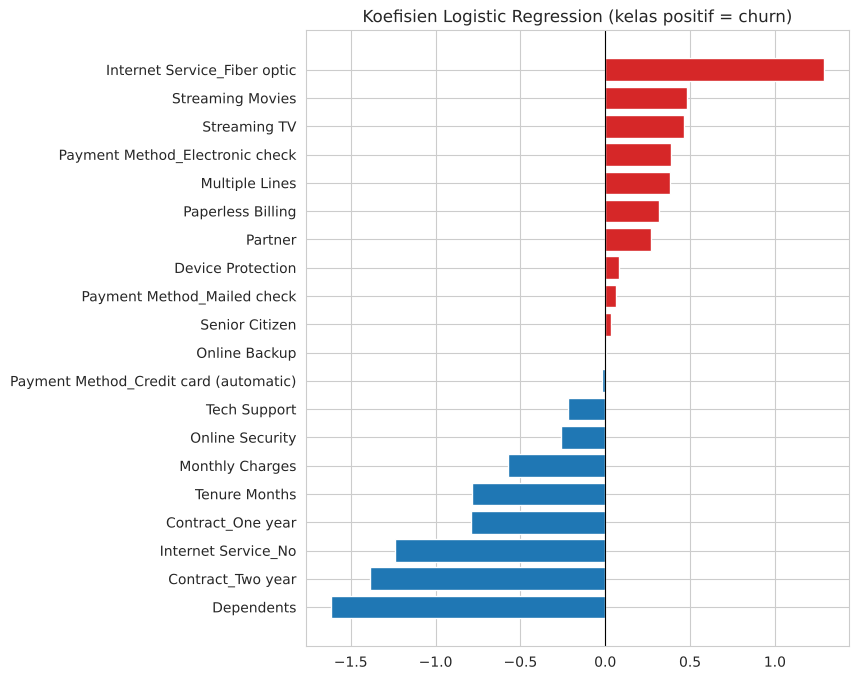

In [21]:
plt.figure(figsize=(7,8))
plt.barh(coef["Fitur"], coef["Koefisien"], color=np.where(coef["Koefisien"] > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Koefisien Logistic Regression (kelas positif = churn)")
plt.gca().invert_yaxis()
plt.show()

In [22]:
# Pembanding sederhana: tingkat churn per kategori Partner dan Dependents (data asli, sebelum model)
for kolom in ["Partner", "Dependents"]:
    print(f"Tingkat churn per {kolom}:")
    print(df.groupby(kolom)["Churn Value"].mean().round(3).to_string(), "\n")

Tingkat churn per Partner:
Partner
No     0.330
Yes    0.197 

Tingkat churn per Dependents:
Dependents
No     0.326
Yes    0.065 



Cara membaca koefisien: koefisien positif menaikkan log-odds churn dan koefisien negatif menurunkannya, dengan fitur lain dianggap tetap. Odds ratio adalah exp(koefisien). Nilai di atas 1 berarti odds churn naik, di bawah 1 berarti turun (odds ratio 2 berarti odds churn jadi dua kali lipat). Untuk `Tenure Months` dan `Monthly Charges` yang sudah distandarisasi, efeknya per kenaikan 1 simpangan baku. Untuk fitur dummy, efeknya dibanding kategori acuan (misalnya `Contract_Two year` dibanding kontrak bulanan).

Yang menaikkan peluang churn:

- `Internet Service_Fiber optic` (odds ratio sekitar 3,6): pelanggan fiber optic jauh lebih berisiko churn dibanding DSL.
- `Streaming Movies` dan `Streaming TV` (sekitar 1,6): pengguna layanan streaming lebih berisiko.
- `Payment Method_Electronic check` (sekitar 1,5), `Multiple Lines` (sekitar 1,5), dan `Paperless Billing` (sekitar 1,4): efeknya lebih kecil.

Yang menurunkan peluang churn:

- `Dependents` (sekitar 0,20), `Contract_Two year` (sekitar 0,25), dan `Internet Service_No` (sekitar 0,29) adalah tiga efek terkuat.
- `Contract_One year` (sekitar 0,45) dan `Tenure Months` (sekitar 0,46 per 1 simpangan baku): kontrak lebih panjang dan masa berlangganan lebih lama menekan churn.
- `Online Security` (sekitar 0,77) dan `Tech Support` (sekitar 0,80): efeknya lebih kecil.

Tiga hal yang kami curigai perlu hati-hati:

1. `Monthly Charges` koefisiennya negatif (odds ratio sekitar 0,56), padahal di EDA pelanggan churn membayar lebih mahal dan korelasinya positif. Kemungkinan besar ini efek multikolinearitas. Tagihan sangat ditentukan jenis layanan (VIF `Monthly Charges` 33,5 dan `Fiber optic` 10,1), dan setelah layanan itu punya koefisien sendiri, sisa pengaruh tagihan jadi berbalik.
2. `Partner` koefisiennya positif (sekitar +0,27), padahal secara sederhana pelanggan yang punya pasangan lebih jarang churn (sel di bawah menunjukkan angkanya). Tandanya berbalik setelah `Dependents` ikut dimasukkan. Kami menduga keduanya berkaitan, tapi belum memeriksanya lebih jauh.
3. Efek `Dependents` sangat kuat, jauh di atas fitur demografis lain. Kami tidak menelusuri asal data ini, jadi kami tidak mau terlalu yakin dengan besarnya efek itu.

## B7. Evaluasi

In [23]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

hasil = {
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}
pd.DataFrame(hasil, index=["Data uji"]).round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Data uji,0.7431,0.5108,0.762,0.6116,0.8465


In [24]:
print(classification_report(y_test, y_pred, target_names=['Bertahan (0)', 'Churn (1)']))

              precision    recall  f1-score   support

Bertahan (0)       0.90      0.74      0.81      1035
   Churn (1)       0.51      0.76      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.76      1409



Confusion matrix model utama (`class_weight='balanced'`):

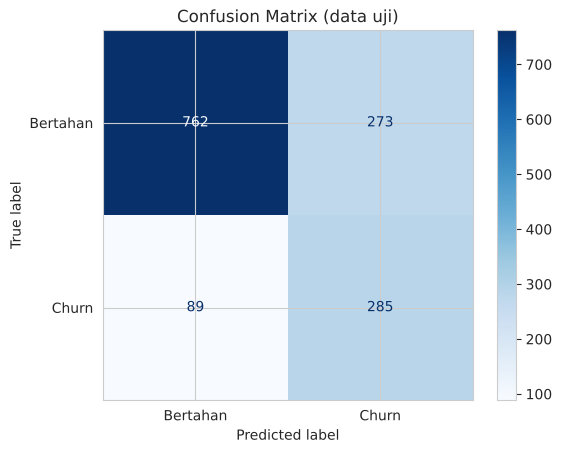

TN=762  FP=273  FN=89  TP=285


In [25]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Bertahan", "Churn"]).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (data uji)")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

Kurva ROC dan nilai AUC:

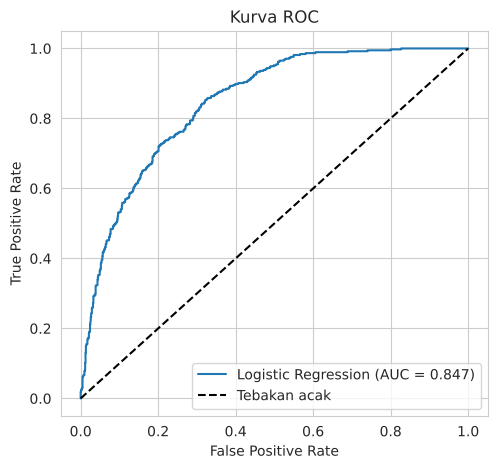

In [26]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(5.5,5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0,1],[0,1],"k--", label="Tebakan acak")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Kurva ROC"); plt.legend(); plt.show()

Untuk melihat dampak penanganan kelas tidak seimbang, kami bandingkan dengan model tanpa `class_weight`.

In [27]:
base = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train, y_train)
yb = base.predict(X_test)
perbandingan = pd.DataFrame({
    "Tanpa class_weight": [accuracy_score(y_test, yb), precision_score(y_test, yb), recall_score(y_test, yb), f1_score(y_test, yb), roc_auc_score(y_test, base.predict_proba(X_test)[:,1])],
    "class_weight=balanced": list(hasil.values()),
}, index=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]).round(4)
perbandingan

,Tanpa class_weight,class_weight=balanced
Accuracy,0.8027,0.7431
Precision,0.6455,0.5108
Recall,0.5695,0.7620
F1-score,0.6051,0.6116
ROC-AUC,0.8464,0.8465


In [28]:
# Confusion matrix model tanpa class_weight, untuk dibandingkan dengan model utama
tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_test, yb).ravel()
print(f"Tanpa class_weight : TN={tn_b}  FP={fp_b}  FN={fn_b}  TP={tp_b}")
print(f"class_weight=balanced: TN={tn}  FP={fp}  FN={fn}  TP={tp}")

Tanpa class_weight : TN=918  FP=117  FN=161  TP=213
class_weight=balanced: TN=762  FP=273  FN=89  TP=285


## B8. Analisis Performa

Ini hasil di data uji (1.409 pelanggan, 374 di antaranya churn):

| Metrik | Tanpa class_weight | `class_weight='balanced'` (model utama) |
|---|---|---|
| Accuracy | 0,803 | 0,743 |
| Precision | 0,646 | 0,511 |
| Recall | 0,570 | 0,762 |
| F1-score | 0,605 | 0,612 |
| ROC-AUC | 0,846 | 0,847 |

Metrik yang menurut kami paling penting di kasus ini adalah recall kelas churn. Yang paling rugi itu kalau pelanggan yang sebenarnya mau pergi malah diprediksi bertahan (false negative), karena perusahaan jadi tidak sempat menawarkan apa-apa. Accuracy kurang cocok dipakai karena datanya tidak seimbang. Model yang selalu menebak "bertahan" saja sudah dapat sekitar 73,5% tanpa menemukan satu pun pelanggan churn. Model tanpa `class_weight` kelihatannya paling akurat (0,803), tapi cuma berhasil menangkap 57% pelanggan churn. F1-score dan ROC-AUC kami pakai sebagai pelengkap.

Efek `class_weight='balanced'`: recall naik dari 0,570 ke 0,762 (sekitar 19 poin persentase), tapi harganya precision turun dari 0,646 ke 0,511 dan accuracy ikut turun ke 0,743. F1-nya hampir sama (0,605 vs 0,612), jadi kami memilihnya bukan karena F1. Alasannya, menurut kami kehilangan pelanggan lebih mahal daripada memberi promo ke pelanggan yang sebenarnya bakal bertahan. Perlu dicatat, biaya sebenarnya tidak ada di dataset, jadi ini cuma asumsi kami. ROC-AUC kedua model sama (sekitar 0,846), artinya kemampuan model membedakan dua kelas tidak berubah, yang bergeser hanya titik potong keputusannya. Mungkin recall yang sama bisa didapat dengan menurunkan threshold di model biasa, tapi itu tidak kami coba.

Soal jenis kesalahan, di model utama hasilnya TN = 762, FP = 273, FN = 89, dan TP = 285. Kesalahan paling banyak adalah false positive (273), yaitu pelanggan yang sebenarnya bertahan tapi diprediksi churn. Dari 558 pelanggan yang ditandai churn, cuma 285 (sekitar 51%) yang benar-benar churn. False negative tinggal 89, jadi sekitar 24% pelanggan churn masih lolos. Di model tanpa `class_weight` kebalikannya: false negative 161 dan false positive cuma 117 (TN = 918, TP = 213).

Soal overfitting, kami belum bisa memastikan. Kami cuma mengevaluasi di satu pembagian data dan tidak membandingkan metrik latih dengan uji. Modelnya sederhana dan data latihnya cukup banyak (5.634 baris), jadi kami tidak menduga overfitting yang parah.

Keterbatasannya:

1. Precision cuma sekitar 51%, jadi kira-kira separuh pelanggan yang ditandai berisiko sebenarnya akan bertahan. Kalau biaya promo retensinya besar, threshold perlu dinaikkan.
2. Logistic Regression mengasumsikan hubungan yang linear di log-odds, jadi interaksi antar fitur tidak tertangkap (misalnya efek fiber optic yang bisa beda untuk tiap jenis kontrak). Random Forest atau Gradient Boosting bisa dicoba.
3. Masih ada multikolinearitas, terutama antara `Monthly Charges` dan jenis internet. Karena itu koefisien tiap fitur, termasuk tanda negatif di `Monthly Charges`, tidak bisa dibaca sendiri-sendiri.
4. Kami belum paham kenapa efek `Dependents` sebesar itu dan kenapa `Partner` tandanya positif (lihat B6), jadi interpretasi demografisnya jangan dipegang terlalu kuat.
5. Threshold tetap 0,5 dan tidak kami setel. Kami juga cuma pakai satu pembagian data, tanpa cross-validation.
6. Kolom lokasi dan `CLTV` tidak dipakai, jadi informasi geografis tidak ikut dimodelkan.
7. Datanya dari satu wilayah (California) dan satu titik waktu, jadi belum tentu berlaku di tempat atau waktu lain. Hubungan yang ketemu juga cuma asosiasi, bukan sebab-akibat.

Kesimpulannya, model dengan `class_weight='balanced'` bisa menangkap sekitar 76% pelanggan churn dengan ROC-AUC sekitar 0,85, dan koefisiennya masih bisa dibaca. Faktor yang paling terkait dengan churn adalah jenis kontrak, lama berlangganan, layanan fiber optic, dan pembayaran electronic check. Konsekuensinya, false positive-nya banyak.

Hasil di data uji (1.409 pelanggan, 374 di antaranya churn):

| Metrik | Tanpa class_weight | `class_weight='balanced'` (model utama) |
|---|---|---|
| Accuracy | 0,803 | 0,743 |
| Precision | 0,646 | 0,511 |
| Recall | 0,570 | 0,762 |
| F1-score | 0,605 | 0,612 |
| ROC-AUC | 0,846 | 0,847 |

Metrik yang paling relevan adalah recall kelas churn. Kesalahan yang paling merugikan di kasus ini adalah false negative, yaitu pelanggan yang akan churn tapi diprediksi bertahan, sehingga perusahaan tidak sempat menawarkan retensi. Accuracy kurang cocok karena datanya tidak seimbang. Model yang selalu menebak "bertahan" sudah mendapat sekitar 73,5% tanpa menemukan satu pun pelanggan churn, dan model tanpa `class_weight` yang terlihat paling akurat (0,803) hanya menangkap 57% pelanggan churn. F1-score dan ROC-AUC kami pakai sebagai pelengkap.

Pengaruh `class_weight='balanced'`: recall naik dari 0,570 ke 0,762 (sekitar 19 poin persentase), tapi precision turun dari 0,646 ke 0,511 dan accuracy turun ke 0,743. F1 hampir tidak berubah (0,605 vs 0,612), jadi kami tidak memilihnya karena F1. Kami memilihnya karena menurut kami melewatkan pelanggan churn lebih mahal daripada menawarkan promo ke pelanggan yang sebenarnya akan bertahan. Rasio biayanya tidak ada di dataset, jadi ini asumsi kami. ROC-AUC kedua model sama (sekitar 0,846), artinya kemampuan model membedakan kedua kelas tidak berubah. Yang bergeser hanya titik potong keputusannya. Recall yang sama mungkin juga bisa dicapai dengan menurunkan threshold pada model biasa, tapi itu tidak kami coba.

Jenis kesalahan. Pada model utama: TN = 762, FP = 273, FN = 89, TP = 285. Kesalahan terbanyak adalah false positive (273), yaitu pelanggan yang sebenarnya bertahan tapi diprediksi churn. Dari 558 pelanggan yang ditandai churn, hanya 285 (sekitar 51%) yang benar-benar churn. False negative tinggal 89, atau sekitar 24% pelanggan churn yang masih terlewat. Pada model tanpa `class_weight` pola kesalahannya terbalik: false negative 161 dan false positive hanya 117 (TN = 918, TP = 213).

Overfitting? Kami hanya mengevaluasi di satu pembagian data dan tidak membandingkan metrik latih dengan uji, jadi kami tidak bisa menyimpulkan dengan pasti. Modelnya sederhana dan datanya cukup besar (5.634 baris latih), jadi overfitting berat tidak kami duga.

Keterbatasan model:

1. Precision hanya sekitar 51%, jadi sekitar separuh pelanggan yang ditandai berisiko sebenarnya akan bertahan. Kalau biaya promo retensi besar, threshold perlu dinaikkan.
2. Logistic Regression mengasumsikan hubungan linear antara fitur dan log-odds, sehingga tidak menangkap interaksi (misalnya efek fiber optic yang bisa berbeda untuk tiap jenis kontrak). Random Forest atau Gradient Boosting bisa dicoba.
3. Masih ada multikolinearitas, terutama antara `Monthly Charges` dan jenis internet. Karena itu koefisien individual, termasuk tanda negatif `Monthly Charges`, tidak boleh dibaca terlepas dari fitur lain.
4. Efek `Dependents` dan tanda positif `Partner` belum kami pahami penyebabnya (lihat B6), jadi interpretasi demografis sebaiknya tidak dipegang terlalu kuat.
5. Threshold klasifikasi tetap 0,5 dan kami tidak menyetelnya. Kami juga hanya memakai satu pembagian data tanpa cross-validation.
6. Kolom lokasi dan `CLTV` tidak dipakai, jadi informasi geografis tidak ikut dimodelkan.
7. Datanya dari satu wilayah (California) dan satu titik waktu, jadi belum tentu berlaku untuk wilayah atau periode lain. Hubungan yang ditemukan juga asosiasi, bukan sebab-akibat.

Kesimpulannya, model dengan `class_weight='balanced'` menangkap sekitar 76% pelanggan churn dengan ROC-AUC sekitar 0,85, dan koefisiennya masih bisa dibaca. Faktor yang paling terkait dengan churn adalah jenis kontrak, lama berlangganan, layanan fiber optic, dan pembayaran electronic check. Harganya adalah banyak false positive.